# Práctica 1: Perceptrón multicapa.

Tu jefe pidió a RH que recolectara datos de desempeño de tus compañeros, los resultados se almacenaron en un csv. El punto critico de estos datos es la satisfacción del empleado, entonces ¿Podremos estimar la satisfacción de los empleados con los datos recabados?.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models


df = pd.read_csv('Extended_Employee_Performance_and_Productivity_Data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  object 
 2   Gender                       100000 non-null  object 
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  object 
 5   Hire_Date                    100000 non-null  object 
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  object 
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64  
 13  

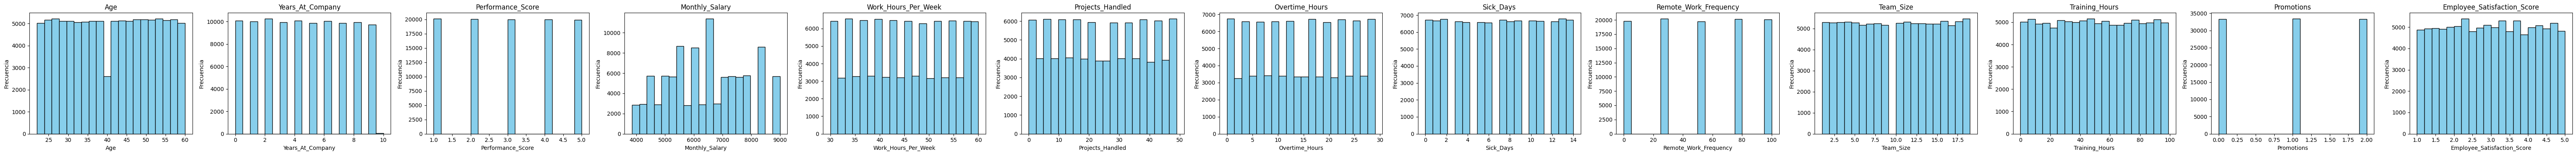

In [2]:
# Filtrar las columnas numéricas
numeric_columns = df.select_dtypes(include=['number']).drop('Employee_ID',axis=1)


# Si numeric_columns es un Index, conviértelo a lista
cols = list(numeric_columns)

fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 4))

for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=20, color='skyblue', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Problemas**, tenemos distribuciones con picos, esos nos indica categorías. Por otro lado, tenemos variables con "valles" en su distribución (distribuciones multimodales) por lo que resultaría óptimo aplicar técnicas de feature engeneering. Por último tenemos distribuciones uniformes, por lo que cada una requeriría un procesamiento indivudual, hagamos la vista gorda e intentemos ajustar un MLP con estos datos, solo estandaricemos nuestros datos.

---

## Implementación de Red:

To**memos los datos numéricos como nuestra variable X, y la variable objetivo como ***'Employee_Satisfaction_Score'***.
- **Actividad 1**: Para todos los strings ``'@modif@'`` que aparescan en el siguiente bloque de código cámbialos para que el código funcione.

In [3]:
X = '@modif@'.drop('Employee_Satisfaction_Score',axis = 1)
y = numeric_columns.'@modif@'
y = y.apply(lambda x: round(x)-1) #Cambiamos la variable objetivo a 5 categorías numéricas

scaler = StandardScaler()
X_standar = scaler.'@modif@'(X)

X_train, X_test, y_train, y_test = '@modif@'(X_standar, y, test_size=0.33, random_state=42)

y_onehot_train = tf.keras.utils.to_categorical(y_train, 5)
y_onehot_test = tf.keras.utils.to_categorical(y_test,5)

SyntaxError: invalid syntax (3357484127.py, line 2)

In [6]:
X = numeric_columns.drop('Employee_Satisfaction_Score', axis=1)
y = numeric_columns['Employee_Satisfaction_Score']
y = y.apply(lambda x: round(x)-1)


scaler = StandardScaler()
X_standar = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_standar, y, test_size=0.33, random_state=42)

y_onehot_train = tf.keras.utils.to_categorical(y_train, 5)
y_onehot_test = tf.keras.utils.to_categorical(y_test, 5)


- **Actividad 2:** Implementa 3 arquitecturas de MLP, cada una con su propio nombre, cambiando la estructura de dichas arquitecturas (capas, neuronas por capa, función de activación, etc). 

In [ ]:
# En las siguientes celdas, construye tu modelo con tensorflow.keras solo la arquitectura

In [7]:
MLP_1 = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(5, activation='softmax')
])

MLP_1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │              85 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,029 (4.02 KB)

 Trainable params: 1,029 (4.02 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
MLP_2 = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(5, activation='softmax')
])

MLP_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 128)                 │           1,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,165 (47.52 KB)

 Trainable params: 12,165 (47.52 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
MLP_3 = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='tanh'),
    layers.Dense(5, activation='softmax')
])

MLP_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 256)                 │           3,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 44,805 (175.02 KB)

 Trainable params: 44,805 (175.02 KB)

 Non-trainable params: 0 (0.00 B)

- **Actividad 3:** Compila y ajusta tus tres modelos con sus respectivos hiperparámetros.

In [ ]:
# En las siguientes celdas, compila y entrena el modelo

In [18]:
# Compilación 
#1.- modelo 1
MLP_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',              
    metrics=['accuracy']
)

#2.- modelo 2
MLP_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

#3.- modelo 3
MLP_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [19]:
# Entrenamiento 
#1.- 
history_1 = MLP_1.fit(
    X_train, y_onehot_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

#2.-
history_2 = MLP_2.fit(
    X_train, y_onehot_train,
    epochs=40,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

#3.-
history_3 = MLP_3.fit(
    X_train, y_onehot_train,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


Epoch 1/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.2788 - loss: 1.5448 - val_accuracy: 0.2544 - val_loss: 1.5674
Epoch 2/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2788 - loss: 1.5446 - val_accuracy: 0.2537 - val_loss: 1.5681
Epoch 3/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2791 - loss: 1.5444 - val_accuracy: 0.2526 - val_loss: 1.5695
Epoch 4/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2814 - loss: 1.5443 - val_accuracy: 0.2521 - val_loss: 1.5668
Epoch 5/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2803 - loss: 1.5441 - val_accuracy: 0.2540 - val_loss: 1.5676
Epoch 6/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2798 - loss: 1.5440 - val_accuracy: 0.2519 - val_loss: 1.5686
Epoch 7/30
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2804 - loss: 1.5438 - val_accuracy: 0.2540 - val_loss: 1.5671
Epoch 8/30
 653/1675 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2743 - loss: 1.5447

KeyboardInterrupt: 

In [12]:
# Evaluar
resultados = {}

for nombre, modelo in [
    ('MLP_1', MLP_1),
    ('MLP_2', MLP_2),
    ('MLP_3', MLP_3)
]:
    loss, accuracy = modelo.evaluate(
        X_test, y_onehot_test, verbose=0
    )
    resultados[nombre] = {
        'Loss': loss,
        'Accuracy': accuracy
    }
    print(f'{nombre}')
    print(f'Loss: {loss:.4f}')
    print(f'Accuracy: {accuracy:.4f}')
    print('-' * 30)

# Comparar
pd.DataFrame(resultados).T



MLP_1
Loss: 1.5653
Accuracy: 0.2545
------------------------------
MLP_2
Loss: 1.6240
Accuracy: 0.2493
------------------------------
MLP_3
Loss: 1.5611
Accuracy: 0.2542
------------------------------


,Loss,Accuracy
MLP_1,1.565316,0.254545
MLP_2,1.624047,0.249333
MLP_3,1.561089,0.254152


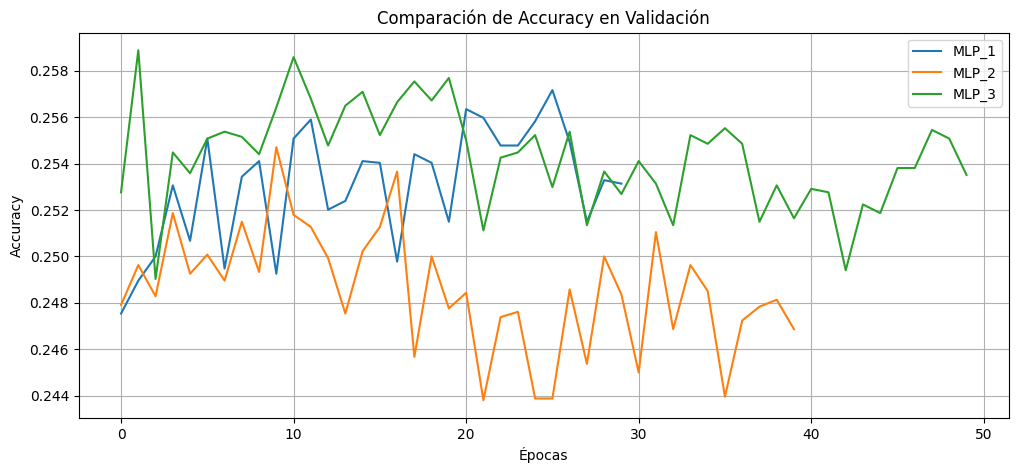

In [13]:

plt.figure(figsize=(12, 5))

plt.plot(history_1.history['val_accuracy'], label='MLP_1')
plt.plot(history_2.history['val_accuracy'], label='MLP_2')
plt.plot(history_3.history['val_accuracy'], label='MLP_3')

plt.title('Comparación de Accuracy en Validación')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()


- **Actividad 4:** Sube tus cambios al repositorio, envía el link de tu repositorio a la actividad 2 de tu checkpoint 2 y contesta las preguntas de dicha actividad.

In [ ]:
¿Con cuál de tus tres modelos te quedarías y por qué?
Me quedo cone l MLP1 porque es el que tiene mayor precision
A pesar de decidir un modelo final ¿Considerarías mejoras a ese mísmo? ¿Cuáles?
Consideraría utilizar variables categóricas